# Лабораторная работа № 1
## Многомерная оптимизация функции генетическим алгоритмом

### Вариант

$N = 10,\ Q = 0,\ Y = 26$

$$V = 1 + ((17N + 7Q + Y) \bmod 20) = 1 + (196 \bmod 20) = 17$$

$$d = 5 + (V \bmod 6) = 10$$

Функция: Sum of Different Powers

### Постановка

$$
\mathbf{x}^* = \arg\min_{\mathbf{x} \in D} f(\mathbf{x}), \qquad
f(\mathbf{x}) = \sum_{i=1}^{d} |x_i|^{\,i+1}, \qquad
D = [-1, 1]^{10}
$$

* Оптимум: $\mathbf{x}^* = \mathbf{0}$, $f^* = 0$
* Ограничения: только границы $-1 \le x_i \le 1$

### Представление особи

* Генотип: $(\mathbf{x}, \sigma)$, $\ \mathbf{x} \in \mathbb{R}^{10}$, $\ \sigma > 0$ — масштаб мутации
* Фенотип: $\mathbf{x}$ (декодирование не нужно)
* Фитнес: $f(\mathbf{x}) \to \min$

## 1. Функции

* Все эволюционные операторы написаны вручную
* Библиотеки: `numpy` (ГПСЧ, массивы), `pandas` (таблицы), `matplotlib` (графики), `scipy.stats` (U-тест)

In [1]:
import time
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

D = 10                 # размерность варианта
LOW, HIGH = -1.0, 1.0  # границы области поиска
F_OPT = 0.0            # теоретический минимум

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

### 1.1. Целевая функция

* `sum_diff_powers(X)`: $X \in \mathbb{R}^{n \times d} \mapsto \big(f(X_1), \dots, f(X_n)\big)$
* `Objective` — счётчик вычислений $f$ (бюджет считается в вычислениях $f$)

In [2]:
def sum_diff_powers(X):
    """f(x) = sum_i |x_i|^(i+1), i = 1..d. X: (n, d) или (d,)."""
    X = np.atleast_2d(X)
    powers = np.arange(2, X.shape[1] + 2)
    return np.sum(np.abs(X) ** powers, axis=1)


class Objective:
    """Обёртка над функцией со счётчиком вычислений."""

    def __init__(self, func, d, low, high):
        self.func, self.d, self.low, self.high = func, d, low, high
        self.evals = 0

    def __call__(self, X):
        X = np.atleast_2d(X)
        self.evals += X.shape[0]
        return self.func(X)

### 1.2. Инициализация и границы

* Инициализация: $x_i \sim U[l, u]$
* Отражение от границы (по умолчанию), $D = [l, u]^d$:

$$
x' = \begin{cases} 2l - x, & x < l \\ x, & l \le x \le u \\ 2u - x, & x > u \end{cases}
$$
$\quad$ (в коде — с периодом $2(u - l)$, корректно и для далёких выходов)

* Альтернатива: `clip`, $x' = \min(\max(x, l), u)$ — скапливает особей на границе

In [3]:
def init_population(rng, n, d, low, high):
    return rng.uniform(low, high, size=(n, d))


def repair_bounds(X, low, high, mode="reflect"):
    if mode == "clip":
        return np.clip(X, low, high)
    width = high - low
    # отражение с периодом 2*width: корректно и для сильных выходов за границу
    Y = np.mod(X - low, 2 * width)
    Y = np.where(Y > width, 2 * width - Y, Y)
    return low + Y

### 1.3. Селекция (минимизация)

**Турнирная** ($T$ — $k = 3$ случайных особи):
$$i^* = \arg\min_{j \in T} f_j$$

**Ранговая** ($r_j = 0$ у худшего, $\mu - 1$ у лучшего, $s = 1.7$):
$$p_j = \frac{2 - s}{\mu} + \frac{2 r_j (s - 1)}{\mu(\mu - 1)}$$

**Рулетка** (масштабирование окном):
$$p_j = \frac{w_j}{\sum_k w_k}, \qquad w_j = f_{\max} - f_j + \varepsilon$$

* Ранговая и турнирная не зависят от масштаба $f$ (важно: $f$ в популяции различаются на порядки)

In [4]:
def select_tournament(rng, fit, n_select, k=3):
    idx = rng.integers(0, len(fit), size=(n_select, k))
    winners = np.argmin(fit[idx], axis=1)
    return idx[np.arange(n_select), winners]


def select_rank(rng, fit, n_select, s=1.7):
    n = len(fit)
    order = np.argsort(-fit)                 # от худшего к лучшему
    ranks = np.empty(n)
    ranks[order] = np.arange(n)              # худший -> 0, лучший -> n-1
    p = (2 - s) / n + 2 * ranks * (s - 1) / (n * (n - 1))
    return rng.choice(n, size=n_select, p=p / p.sum())


def select_roulette(rng, fit, n_select, eps=1e-12):
    w = fit.max() - fit + eps                # масштабирование окном
    return rng.choice(len(fit), size=n_select, p=w / w.sum())


SELECTIONS = {"tournament": select_tournament, "rank": select_rank, "roulette": select_roulette}

### 1.4. Кроссовер

Родители $\mathbf{p}^1, \mathbf{p}^2$, потомки $\mathbf{c}^1, \mathbf{c}^2$, применяется к паре с вероятностью $p_c$.

**SBX** ($\eta = 15$), для каждой координаты с вероятностью $0.5$:
$$
\beta = \begin{cases} (2u)^{\frac{1}{\eta+1}}, & u \le 0.5 \\ \left(\frac{1}{2(1-u)}\right)^{\frac{1}{\eta+1}}, & u > 0.5 \end{cases},
\qquad
c^{1,2}_i = \tfrac12\big[(1 \pm \beta)\,p^1_i + (1 \mp \beta)\,p^2_i\big]
$$

**BLX-α** ($\alpha = 0.5$):
$$
c_i \sim U\big[m_i - \alpha I_i,\ M_i + \alpha I_i\big], \quad m_i = \min(p^1_i, p^2_i),\ M_i = \max(p^1_i, p^2_i),\ I_i = M_i - m_i
$$

**Арифметический**:
$$
\mathbf{c}^1 = \lambda \mathbf{p}^1 + (1 - \lambda)\mathbf{p}^2, \quad \mathbf{c}^2 = (1 - \lambda)\mathbf{p}^1 + \lambda \mathbf{p}^2, \quad \lambda \sim U[0, 1]
$$

In [5]:
def crossover_sbx(rng, P1, P2, eta=15.0):
    u = rng.random(P1.shape)
    beta = np.where(u <= 0.5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u))) ** (1 / (eta + 1)))
    C1 = 0.5 * ((1 + beta) * P1 + (1 - beta) * P2)
    C2 = 0.5 * ((1 - beta) * P1 + (1 + beta) * P2)
    # каждая координата меняется с вероятностью 0.5 (как в стандартном SBX)
    swap = rng.random(P1.shape) < 0.5
    return np.where(swap, C1, P1), np.where(swap, C2, P2)


def crossover_blx(rng, P1, P2, alpha=0.5):
    lo, hi = np.minimum(P1, P2), np.maximum(P1, P2)
    span = hi - lo
    a, b = lo - alpha * span, hi + alpha * span
    return rng.uniform(a, b), rng.uniform(a, b)


def crossover_arith(rng, P1, P2):
    lam = rng.random((P1.shape[0], 1))
    return lam * P1 + (1 - lam) * P2, (1 - lam) * P1 + lam * P2


CROSSOVERS = {"sbx": crossover_sbx, "blx": crossover_blx, "arith": crossover_arith}

### 1.5. Мутация

Каждый ген с вероятностью $p_m = 1/d$:
$$
x_i' = x_i + \sigma\, \mathcal{N}(0, 1)
$$

**Фиксированный** $\sigma$:
$$\sigma = \sigma_0 (u - l), \qquad \sigma_0 = 0.1$$

**Самоадаптивный** $\sigma$:
$$\sigma_{\text{child}} = \sqrt{\sigma_{p_1}\sigma_{p_2}} \cdot e^{\tau \mathcal{N}(0,1)}, \qquad \tau = \frac{1}{\sqrt{d}}, \qquad \sigma \in [10^{-12}, 1]$$

* При самоадаптации $\sigma$ наследуется и отбирается вместе с особью → уменьшается у оптимума

In [6]:
def mutate_gaussian(rng, X, sigma, pm):
    """sigma: скаляр или массив (n,) — масштаб для каждой особи."""
    sigma = np.broadcast_to(np.asarray(sigma, dtype=float).reshape(-1, 1), (X.shape[0], 1))
    mask = rng.random(X.shape) < pm
    return X + mask * rng.normal(0.0, 1.0, X.shape) * sigma


def self_adapt_sigma(rng, sigma, tau, sigma_min=1e-12, sigma_max=1.0):
    return np.clip(sigma * np.exp(tau * rng.normal(size=sigma.shape)), sigma_min, sigma_max)

### 1.6. ГА: схема

```
P(0) ~ U(D),  оценка f
   │
   ▼
┌─► evals + (μ−e) > бюджет ? ──да──► вернуть x_best
│      │ нет
│      ▼
│   селекция 2·⌈(μ−e)/2⌉ родителей
│      ▼
│   кроссовер пар (p_c)
│      ▼
│   самоадаптация σ, мутация (p_m)
│      ▼
│   отражение от границ, оценка f
│      ▼
│   P(t+1) = e лучших из P(t) ∪ (μ−e) потомков
└──────┘
```

* Элитизм: $e = 2$
* Остановка: бюджет вычислений $f$
* Все параметры — в `GAConfig`

In [7]:
@dataclass
class GAConfig:
    pop_size: int = 50            # μ — размер популяции
    max_evals: int = 10_000       # бюджет вычислений f
    selection: str = "tournament" # tournament | rank | roulette
    tournament_k: int = 3
    rank_s: float = 1.7
    crossover: str = "sbx"        # sbx | blx | arith
    pc: float = 0.9               # вероятность кроссовера для пары
    sbx_eta: float = 15.0
    blx_alpha: float = 0.5
    pm: float = 0.1               # вероятность мутации гена (= 1/d)
    sigma0: float = 0.1           # начальный масштаб мутации, доля ширины области
    adaptive: bool = True         # самоадаптация σ
    elite: int = 2                # число элитных особей
    bounds: str = "reflect"       # reflect | clip


def run_ga(cfg: GAConfig, seed: int, func=sum_diff_powers, d=D, low=LOW, high=HIGH, record_pop=False):
    """Один запуск ГА. Возвращает лучшее решение и историю по поколениям.
    record_pop=True дополнительно сохраняет популяцию каждого поколения (для визуализации)."""
    rng = np.random.default_rng(seed)
    obj = Objective(func, d, low, high)
    mu, e = cfg.pop_size, cfg.elite
    n_off = mu - e
    n_pairs = (n_off + 1) // 2
    tau = 1 / np.sqrt(d)
    select = SELECTIONS[cfg.selection]
    sel_kw = {"tournament": {"k": cfg.tournament_k}, "rank": {"s": cfg.rank_s}, "roulette": {}}[cfg.selection]
    cross = CROSSOVERS[cfg.crossover]
    cx_kw = {"sbx": {"eta": cfg.sbx_eta}, "blx": {"alpha": cfg.blx_alpha}, "arith": {}}[cfg.crossover]

    pop = init_population(rng, mu, d, low, high)
    sig = np.full(mu, cfg.sigma0 * (high - low))
    fit = obj(pop)
    best_i = np.argmin(fit)
    best_x, best_f = pop[best_i].copy(), fit[best_i]
    hist = [(obj.evals, best_f, fit.mean(), np.median(sig))]
    pops = [pop.copy()] if record_pop else None

    while obj.evals + n_off <= cfg.max_evals:
        # 1. селекция
        par = select(rng, fit, 2 * n_pairs, **sel_kw)
        i1, i2 = par[:n_pairs], par[n_pairs:]
        P1, P2 = pop[i1], pop[i2]
        # 2. кроссовер (пары, не прошедшие по p_c, копируются без изменений)
        C1, C2 = cross(rng, P1, P2, **cx_kw)
        do_cx = (rng.random(n_pairs) < cfg.pc)[:, None]
        C1, C2 = np.where(do_cx, C1, P1), np.where(do_cx, C2, P2)
        child = np.vstack([C1, C2])[:n_off]
        # 3. мутация (σ потомка — среднее геометрическое σ родителей)
        if cfg.adaptive:
            s_par = np.sqrt(sig[i1] * sig[i2])
            s_child = self_adapt_sigma(rng, np.concatenate([s_par, s_par])[:n_off], tau)
        else:
            s_child = np.full(n_off, cfg.sigma0 * (high - low))
        child = mutate_gaussian(rng, child, s_child, cfg.pm)
        # 4. обработка границ и оценка
        child = repair_bounds(child, low, high, cfg.bounds)
        f_child = obj(child)
        # 5. элитизм: e лучших родителей переходят в следующее поколение
        elite_idx = np.argsort(fit)[:e]
        pop = np.vstack([pop[elite_idx], child])
        fit = np.concatenate([fit[elite_idx], f_child])
        sig = np.concatenate([sig[elite_idx], s_child])
        i = np.argmin(fit)
        if fit[i] < best_f:
            best_x, best_f = pop[i].copy(), fit[i]
        hist.append((obj.evals, best_f, fit.mean(), np.median(sig)))
        if record_pop:
            pops.append(pop.copy())

    history = pd.DataFrame(hist, columns=["evals", "best", "mean", "sigma"])
    return {"best_x": best_x, "best_f": best_f, "evals": obj.evals, "history": history, "populations": pops}

### 1.7. Базовые методы

**Случайный поиск:**
$$\mathbf{x}_t \sim U(D), \qquad f_{\text{best}} = \min_t f(\mathbf{x}_t)$$

**Локальный поиск (1+1)** с фиксированным шагом $h$:
$$\mathbf{y} = \mathbf{x} + h(u - l)\,\mathcal{N}(\mathbf{0}, I), \qquad \mathbf{x} \leftarrow \mathbf{y}\ \text{ если } f(\mathbf{y}) \le f(\mathbf{x})$$

* История пишется в тех же точках `evals`, что у ГА

In [8]:
def run_random_search(max_evals, seed, checkpoints, func=sum_diff_powers, d=D, low=LOW, high=HIGH):
    rng = np.random.default_rng(seed)
    obj = Objective(func, d, low, high)
    fvals = obj(rng.uniform(low, high, size=(max_evals, d)))
    best_curve = np.minimum.accumulate(fvals)
    i = np.argmin(fvals)
    history = pd.DataFrame({"evals": checkpoints, "best": best_curve[np.asarray(checkpoints) - 1]})
    return {"best_f": fvals[i], "evals": obj.evals, "history": history}


def run_hill_climb(max_evals, seed, checkpoints, step=0.1, func=sum_diff_powers, d=D, low=LOW, high=HIGH):
    rng = np.random.default_rng(seed)
    obj = Objective(func, d, low, high)
    x = rng.uniform(low, high, d)
    fx = obj(x)[0]
    curve = np.empty(max_evals)
    curve[0] = fx
    for t in range(1, max_evals):
        y = repair_bounds(x + rng.normal(0, step * (high - low), d), low, high)
        fy = obj(y)[0]
        if fy <= fx:
            x, fx = y, fy
        curve[t] = fx
    history = pd.DataFrame({"evals": checkpoints, "best": curve[np.asarray(checkpoints) - 1]})
    return {"best_f": fx, "evals": obj.evals, "history": history}

### 1.8. Серии, статистика, графики

* `run_series`: seed $= 1000 + r$, $\ r = 0, \dots, R-1$
* `summarize`: $\min,\ \bar f,\ \operatorname{med},\ s,\ \max$, доля успехов $\ \mathbb{P}(f < 10^{-8})$, время
* `mann_whitney`: двусторонний U-тест, $H_0$: распределения итоговых $f$ совпадают
* `plot_convergence`: медиана + квантили $[Q_{25}, Q_{75}]$, лог-шкала

In [9]:
SUCCESS_EPS = 1e-8


def run_series(runner, n_runs=30, base_seed=1000):
    """runner(seed) -> dict. Возвращает таблицу итогов и список историй."""
    rows, histories = [], []
    for r in range(n_runs):
        seed = base_seed + r
        t0 = time.perf_counter()
        res = runner(seed)
        rows.append({"seed": seed, "best_f": res["best_f"], "evals": res["evals"],
                     "time_s": time.perf_counter() - t0})
        histories.append(res["history"])
    return pd.DataFrame(rows), histories


def summarize(runs: pd.DataFrame, name=""):
    f = runs["best_f"]
    return pd.Series({"best": f.min(), "mean": f.mean(), "median": f.median(), "std": f.std(),
                      "worst": f.max(), f"success(f<{SUCCESS_EPS:g})": (f < SUCCESS_EPS).mean(),
                      "evals": runs["evals"].mean(), "time_s": runs["time_s"].mean()}, name=name)


def curves_matrix(histories, col="best"):
    """Матрица (runs, generations) значений колонки col и общая ось evals."""
    return np.vstack([h[col].to_numpy() for h in histories]), histories[0]["evals"].to_numpy()


def plot_convergence(series: dict, title, ax=None, band="iqr", show_minmax=False):
    """series: {label: histories}. Рисует медиану и диапазон по запускам."""
    if ax is None:
        _, ax = plt.subplots()
    for label, histories in series.items():
        M, x = curves_matrix(histories)
        M = np.maximum(M, 1e-300)                       # для лог-шкалы
        line, = ax.plot(x, np.median(M, axis=0), label=f"{label} (медиана)")
        if band == "iqr":
            ax.fill_between(x, np.quantile(M, 0.25, axis=0), np.quantile(M, 0.75, axis=0),
                            color=line.get_color(), alpha=0.25)
        if show_minmax:
            ax.plot(x, M.min(axis=0), color=line.get_color(), ls=":", lw=1)
            ax.plot(x, M.max(axis=0), color=line.get_color(), ls="--", lw=1)
    ax.set_yscale("log")
    ax.set_xlabel("число вычислений f")
    ax.set_ylabel("лучшее найденное f (log)")
    ax.set_title(title)
    ax.legend()
    return ax


def mann_whitney(a, b):
    """Двусторонний U-тест Манна—Уитни для итоговых значений двух серий."""
    return stats.mannwhitneyu(a, b, alternative="two-sided").pvalue

### 1.9. Проверки

* $f(\mathbf{0}) = 0$, $\ f(\mathbf{1}) = d$, $\ f(0.5, 0.5) = 0.375$
* отражение: результат $\in D$, $\ 1.2 \mapsto 0.8$, $\ -1.3 \mapsto -0.7$
* селекция: $\overline{f}_{\text{выбранных}} < \overline{f}_{\text{популяции}}$
* одинаковый seed → одинаковый результат

In [10]:
assert sum_diff_powers(np.zeros(D))[0] == 0.0
assert np.isclose(sum_diff_powers(np.ones(D))[0], D)              # |1|^p = 1 для каждой координаты
assert np.isclose(sum_diff_powers(np.array([0.5, 0.5]))[0], 0.25 + 0.125)

_rng = np.random.default_rng(0)
_X = _rng.uniform(-5, 5, size=(1000, D))
_R = repair_bounds(_X, LOW, HIGH)
assert _R.min() >= LOW and _R.max() <= HIGH
assert np.allclose(repair_bounds(np.array([[1.2, -1.3, 0.4]]), LOW, HIGH), [[0.8, -0.7, 0.4]])

_fit = sum_diff_powers(_R)
for name, sel in SELECTIONS.items():
    picked = sel(_rng, _fit, 5000)
    # селекция должна в среднем выбирать особей лучше среднего по популяции
    assert _fit[picked].mean() < _fit.mean(), name
for name, cx in CROSSOVERS.items():
    c1, c2 = cx(_rng, _R[:10], _R[10:20])
    assert c1.shape == c2.shape == (10, D), name

_a = run_ga(GAConfig(max_evals=2000), seed=42)
_b = run_ga(GAConfig(max_evals=2000), seed=42)
assert _a["best_f"] == _b["best_f"] and _a["evals"] <= 2000
print("Все проверки пройдены. Пробный запуск ГА (2000 вычислений): f =", _a["best_f"])

Все проверки пройдены. Пробный запуск ГА (2000 вычислений): f = 3.881457584054371e-05


## 2. Базовая серия

* Бюджет: $10\,000 = 1000 \cdot d$ вычислений $f$
* Запусков: $R = 30$, seed $1000 \dots 1029$
* Успех: $f < 10^{-8}$

In [11]:
N_RUNS = 30
BASE_SEED = 1000
BASE = GAConfig()

params = pd.Series(asdict(BASE), name="значение").to_frame()
params.loc["n_runs"] = N_RUNS
params.loc["seeds"] = f"{BASE_SEED}..{BASE_SEED + N_RUNS - 1}"
params.loc["инициализация"] = "равномерная в D"
params.loc["критерий остановки"] = "исчерпание бюджета вычислений f"
params.to_csv(RESULTS / "base_config.csv")
params

,значение
pop_size,50
max_evals,10000
selection,tournament
tournament_k,3
rank_s,1.7
crossover,sbx
pc,0.9
sbx_eta,15.0
blx_alpha,0.5
pm,0.1


### 2.2. ГА, 30 запусков

In [12]:
ga_runs, ga_hist = run_series(lambda s: run_ga(BASE, s), N_RUNS, BASE_SEED)
ga_runs.to_csv(RESULTS / "runs_ga_base.csv", index=False)
summarize(ga_runs, "ГА (база)").to_frame().T

,best,mean,median,std,worst,success(f<1e-08),evals,time_s
ГА (база),1.773360e-13,3.479459e-10,2.322518e-11,7.299784e-10,2.680537e-09,1.0,9986.0,0.017573


Лучшее решение (воспроизводится по seed):

In [13]:
best_seed = int(ga_runs.loc[ga_runs.best_f.idxmin(), "seed"])
best_res = run_ga(BASE, best_seed)   # воспроизведение по seed
print(f"seed = {best_seed}, f = {best_res['best_f']:.3e}")
pd.DataFrame({"x_i": best_res["best_x"], "|x_i|^(i+1)": np.abs(best_res["best_x"]) ** np.arange(2, D + 2)},
             index=[f"x{i}" for i in range(1, D + 1)])

seed = 1023, f = 1.773e-13


,x_i,|x_i|^(i+1)
x1,4.205475e-07,1.768602e-13
x2,-4.942161e-06,1.207121e-16
x3,1.279240e-04,2.677981e-16
x4,-6.116689e-04,8.562133e-17
x5,-1.047221e-03,1.318952e-18
x6,-1.502164e-03,1.725921e-20
x7,-9.415135e-04,6.174649e-25
x8,7.011520e-03,4.095527e-20
x9,3.464136e-03,2.488563e-25
x10,-2.065876e-02,2.925147e-19


### 2.3. Сравнение с базовыми методами

* Тот же бюджет $10^4$, те же seed
* Локальный поиск: $h = 0.1$ и $h = 0.01$

In [14]:
CHECKPOINTS = ga_hist[0]["evals"].to_numpy()

rs_runs, rs_hist = run_series(lambda s: run_random_search(BASE.max_evals, s, CHECKPOINTS), N_RUNS, BASE_SEED)
hc_runs, hc_hist = run_series(lambda s: run_hill_climb(BASE.max_evals, s, CHECKPOINTS, step=0.1), N_RUNS, BASE_SEED)
hc2_runs, hc2_hist = run_series(lambda s: run_hill_climb(BASE.max_evals, s, CHECKPOINTS, step=0.01), N_RUNS, BASE_SEED)

rs_runs.to_csv(RESULTS / "runs_random_search.csv", index=False)
hc_runs.to_csv(RESULTS / "runs_hill_climb_0.1.csv", index=False)
hc2_runs.to_csv(RESULTS / "runs_hill_climb_0.01.csv", index=False)

baseline_table = pd.DataFrame([
    summarize(ga_runs, "ГА (база)"),
    summarize(rs_runs, "Случайный поиск"),
    summarize(hc_runs, "Локальный поиск, шаг 0.1"),
    summarize(hc2_runs, "Локальный поиск, шаг 0.01"),
])
baseline_table.to_csv(RESULTS / "summary_baselines.csv")
baseline_table.style.format("{:.3e}", subset=["best", "mean", "median", "std", "worst"]).format(
    "{:.3f}", subset=["time_s"])

,best,mean,median,std,worst,success(f<1e-08),evals,time_s
ГА (база),1.773e-13,3.479e-10,2.323e-11,7.300e-10,2.681e-09,1.000000,9986.000000,0.018
Случайный поиск,3.904e-03,1.956e-02,1.922e-02,1.045e-02,5.041e-02,0.000000,10000.000000,0.001
"Локальный поиск, шаг 0.1",1.054e-05,1.358e-04,1.227e-04,1.127e-04,5.534e-04,0.000000,10000.000000,0.082
"Локальный поиск, шаг 0.01",1.722e-08,2.145e-07,1.757e-07,1.381e-07,6.180e-07,0.000000,10000.000000,0.082


In [15]:
for name, runs in [("случайный поиск", rs_runs), ("локальный поиск 0.1", hc_runs), ("локальный поиск 0.01", hc2_runs)]:
    print(f"ГА vs {name}: p-value U-теста Манна—Уитни = {mann_whitney(ga_runs.best_f, runs.best_f):.2e}")

ГА vs случайный поиск: p-value U-теста Манна—Уитни = 3.02e-11
ГА vs локальный поиск 0.1: p-value U-теста Манна—Уитни = 3.02e-11
ГА vs локальный поиск 0.01: p-value U-теста Манна—Уитни = 3.02e-11


### 2.4. Сходимость

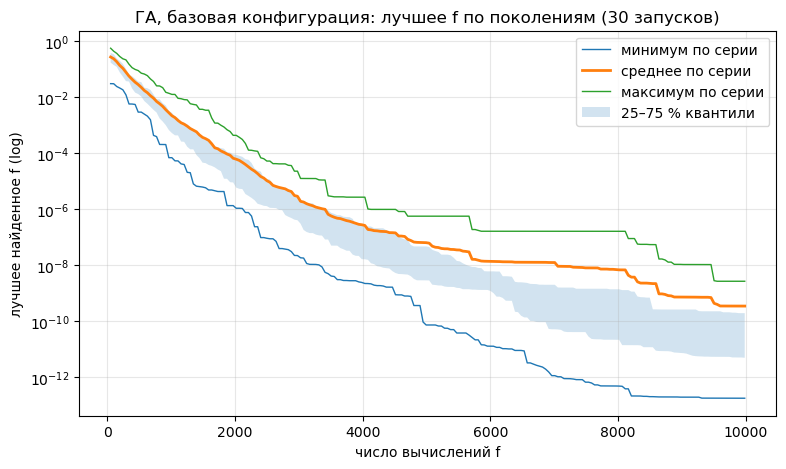

In [16]:
fig, ax = plt.subplots()
M, x = curves_matrix(ga_hist)
ax.plot(x, M.min(axis=0), label="минимум по серии", lw=1)
ax.plot(x, M.mean(axis=0), label="среднее по серии", lw=2)
ax.plot(x, M.max(axis=0), label="максимум по серии", lw=1)
ax.fill_between(x, np.quantile(M, 0.25, axis=0), np.quantile(M, 0.75, axis=0), alpha=0.2, label="25–75 % квантили")
ax.set_yscale("log")
ax.set_xlabel("число вычислений f")
ax.set_ylabel("лучшее найденное f (log)")
ax.set_title(f"ГА, базовая конфигурация: лучшее f по поколениям ({N_RUNS} запусков)")
ax.legend()
fig.savefig(RESULTS / "convergence_ga_base.png", dpi=120, bbox_inches="tight")
plt.show()

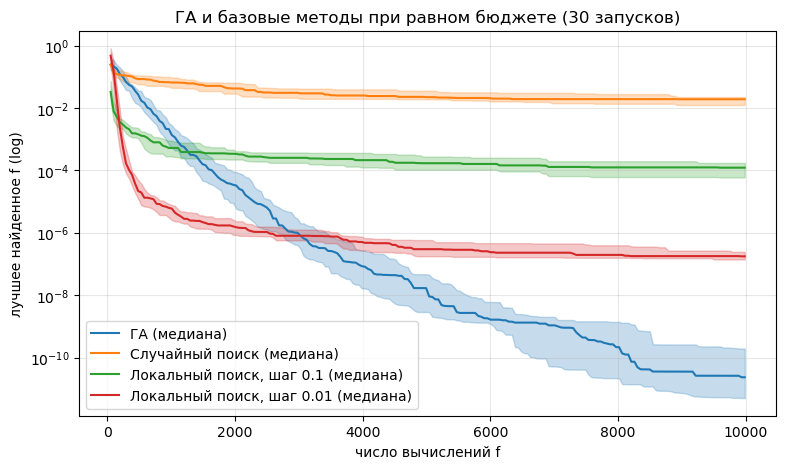

In [17]:
fig, ax = plt.subplots()
plot_convergence({"ГА": ga_hist, "Случайный поиск": rs_hist,
                  "Локальный поиск, шаг 0.1": hc_hist, "Локальный поиск, шаг 0.01": hc2_hist},
                 f"ГА и базовые методы при равном бюджете ({N_RUNS} запусков)", ax=ax)
fig.savefig(RESULTS / "convergence_vs_baselines.png", dpi=120, bbox_inches="tight")
plt.show()

Медиана $\sigma$ при самоадаптации:

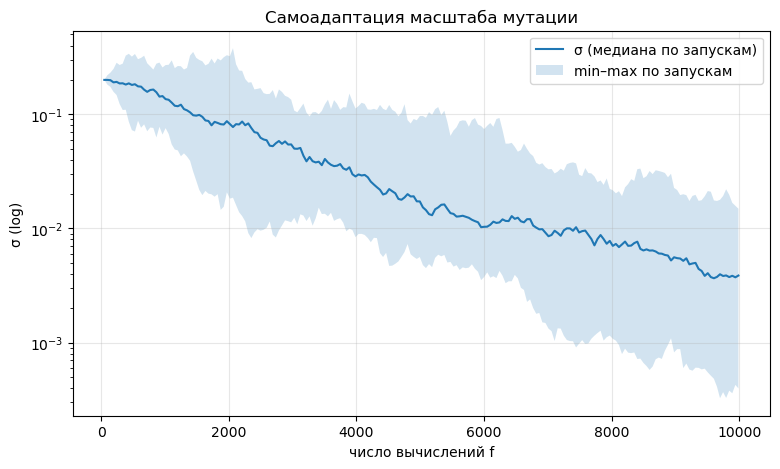

In [18]:
fig, ax = plt.subplots()
S_, x = curves_matrix(ga_hist, "sigma")
ax.plot(x, np.median(S_, axis=0), label="σ (медиана по запускам)")
ax.fill_between(x, S_.min(axis=0), S_.max(axis=0), alpha=0.2, label="min–max по запускам")
ax.set_yscale("log")
ax.set_xlabel("число вычислений f")
ax.set_ylabel("σ (log)")
ax.set_title("Самоадаптация масштаба мутации")
ax.legend()
fig.savefig(RESULTS / "sigma_adaptation.png", dpi=120, bbox_inches="tight")
plt.show()

### 2.5. Итоги базовой серии

| метод | $\operatorname{med} f$ | $\max f$ | успех |
|---|---|---|---|
| ГА | $2.3 \cdot 10^{-11}$ | $2.7 \cdot 10^{-9}$ | $30/30$ |
| случайный поиск | $1.9 \cdot 10^{-2}$ | $5.0 \cdot 10^{-2}$ | $0/30$ |
| локальный, $h = 0.1$ | $1.2 \cdot 10^{-4}$ | $5.5 \cdot 10^{-4}$ | $0/30$ |
| локальный, $h = 0.01$ | $1.8 \cdot 10^{-7}$ | $6.2 \cdot 10^{-7}$ | $0/30$ |

* U-тест ГА против каждого: $p = 3 \cdot 10^{-11}$ (полное разделение выборок)
* $\sigma$: $0.2 \to 0.004$ (≈ в 50 раз) — шаг уменьшается у оптимума

### 2.6. Почему функция трудна

$f$ выпукла и унимодальна, трудность — **анизотропия**:

1. Порог точности по координате: $|x_i|^{i+1} < \varepsilon \iff |x_i| < \varepsilon^{1/(i+1)}$

| $\varepsilon = 10^{-8}$ | $x_1$ | $x_2$ | $x_5$ | $x_{10}$ |
|---|---|---|---|---|
| $\varepsilon^{1/(i+1)}$ | $10^{-4}$ | $2 \cdot 10^{-3}$ | $0.046$ | $0.19$ |

$\quad$ → один шаг не подходит всем координатам

2. Плато: $\dfrac{\partial f}{\partial x_i} = (i+1)\,|x_i|^{i}\operatorname{sign}x_i \approx 0$ при больших $i$
3. Случайный поиск: $\ \mathbb{P}(f < \varepsilon) \le \mathbb{P}(|x_1| < \varepsilon^{1/2}) = \varepsilon^{1/2} = 10^{-4}$ на одну пробу, и это только по $x_1$
4. Локальный поиск с фиксированным $h$: шаг не уменьшается → плато ($h = 0.1 \to 10^{-4}$, $h = 0.01 \to 10^{-7}$)

## 3. Влияние одного фактора

* База `BASE`, меняется один параметр
* Бюджет, seed и остальное — одинаково
* $p$ — U-тест против базы

In [19]:
def factor_study(name, variants: dict):
    """variants: {подпись: GAConfig}. Возвращает таблицу статистик, итоги и истории."""
    table, finals, hists = [], {}, {}
    for label, cfg in variants.items():
        runs, hist = run_series(lambda s: run_ga(cfg, s), N_RUNS, BASE_SEED)
        runs.to_csv(RESULTS / f"runs_{name}_{label}.csv".replace(" ", "_").replace("=", ""), index=False)
        row = summarize(runs, label)
        row["p_vs_base"] = mann_whitney(runs.best_f, ga_runs.best_f) if cfg != BASE else np.nan
        table.append(row)
        finals[label], hists[label] = runs.best_f.to_numpy(), hist
    table = pd.DataFrame(table)
    table.to_csv(RESULTS / f"summary_{name}.csv")
    return table, finals, hists


def plot_factor(name, title, hists):
    fig, ax = plt.subplots()
    plot_convergence(hists, title, ax=ax)
    fig.savefig(RESULTS / f"factor_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


FMT = {c: "{:.2e}" for c in ["best", "mean", "median", "std", "worst", "p_vs_base"]}

### 3.1. Масштаб мутации

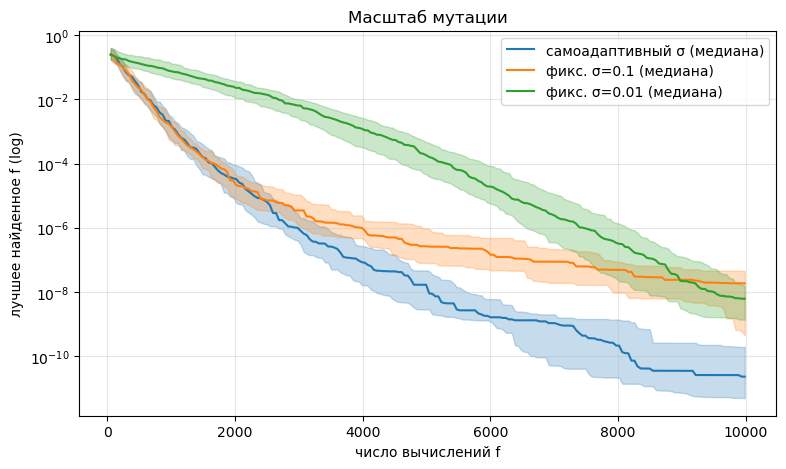

,best,mean,median,std,worst,success(f<1e-08),evals,time_s,p_vs_base
самоадаптивный σ,1.77e-13,3.48e-10,2.32e-11,7.30e-10,2.68e-09,1.000000,9986.000000,0.017713,nan
фикс. σ=0.1,1.03e-11,3.91e-08,1.86e-08,5.68e-08,2.14e-07,0.433333,9986.000000,0.016263,1.36e-07
фикс. σ=0.01,4.67e-12,2.47e-08,6.19e-09,5.87e-08,3.10e-07,0.733333,9986.000000,0.016283,7.09e-08


In [20]:
mut_tab, mut_fin, mut_hist = factor_study("mutation", {
    "самоадаптивный σ": BASE,
    "фикс. σ=0.1": replace(BASE, adaptive=False, sigma0=0.1),
    "фикс. σ=0.01": replace(BASE, adaptive=False, sigma0=0.01),
})
plot_factor("mutation", "Масштаб мутации", mut_hist)
mut_tab.style.format(FMT)

### 3.2. Размер популяции $\mu$

Число поколений: $\ G = \left\lfloor \dfrac{10^4 - \mu}{\mu - e} \right\rfloor$

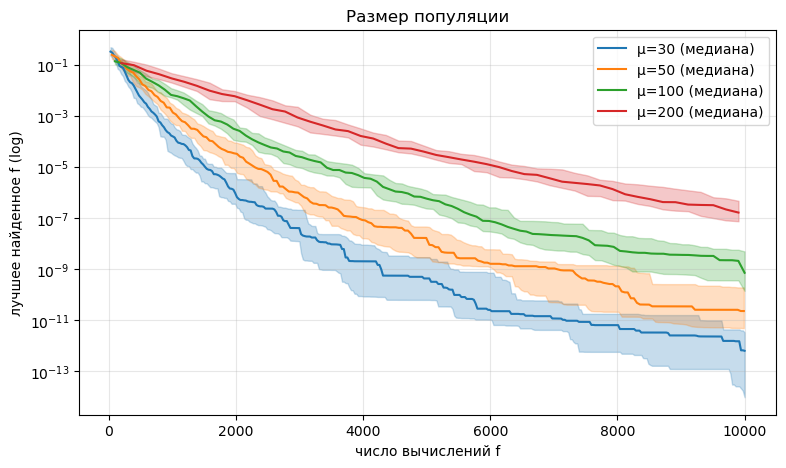

,best,mean,median,std,worst,success(f<1e-08),evals,time_s,p_vs_base
μ=30,1.01e-17,6.39e-12,6.46e-13,1.80e-11,9.73e-11,1.000000,9998.000000,0.027147,7.60e-07
μ=50,1.77e-13,3.48e-10,2.32e-11,7.30e-10,2.68e-09,1.000000,9986.000000,0.017640,nan
μ=100,1.22e-12,4.16e-09,7.29e-10,7.13e-09,3.55e-08,0.900000,9998.000000,0.010982,1.43e-05
μ=200,2.04e-08,4.41e-07,1.65e-07,6.59e-07,2.71e-06,0.000000,9902.000000,0.007785,3.02e-11


In [21]:
pop_tab, pop_fin, pop_hist = factor_study("popsize", {
    f"μ={m}": (BASE if m == BASE.pop_size else replace(BASE, pop_size=m)) for m in [30, 50, 100, 200]
})
plot_factor("popsize", "Размер популяции", pop_hist)
pop_tab.style.format(FMT)

### 3.3. Селекция

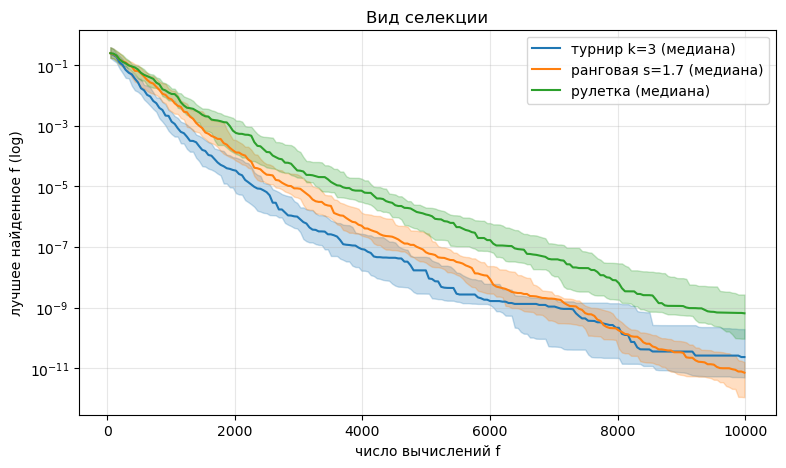

,best,mean,median,std,worst,success(f<1e-08),evals,time_s,p_vs_base
турнир k=3,1.77e-13,3.48e-10,2.32e-11,7.30e-10,2.68e-09,1.000000,9986.000000,0.018040,nan
ранговая s=1.7,3.11e-15,2.16e-11,7.08e-12,4.37e-11,1.98e-10,1.000000,9986.000000,0.020389,5.08e-03
рулетка,7.41e-12,4.02e-09,6.46e-10,1.15e-08,6.28e-08,0.933333,9986.000000,0.023241,8.15e-05


In [22]:
sel_tab, sel_fin, sel_hist = factor_study("selection", {
    "турнир k=3": BASE,
    "ранговая s=1.7": replace(BASE, selection="rank"),
    "рулетка": replace(BASE, selection="roulette"),
})
plot_factor("selection", "Вид селекции", sel_hist)
sel_tab.style.format(FMT)

### 3.4. Кроссовер

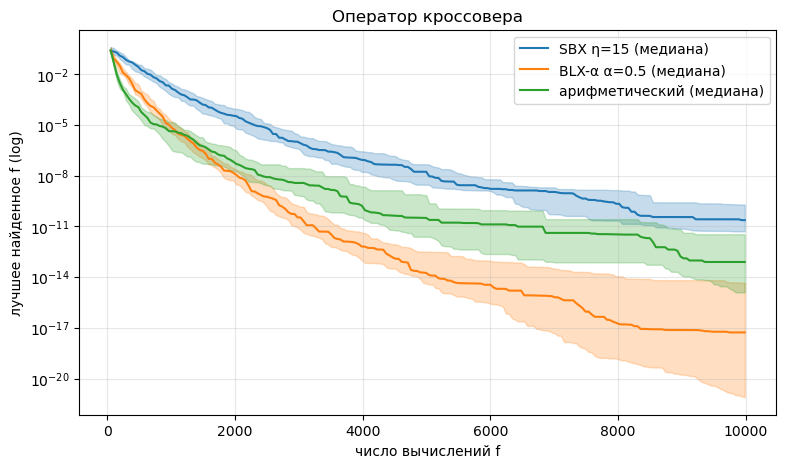

,best,mean,median,std,worst,success(f<1e-08),evals,time_s,p_vs_base
SBX η=15,1.77e-13,3.48e-10,2.32e-11,7.30e-10,2.68e-09,1.000000,9986.000000,0.018426,nan
BLX-α α=0.5,1.88e-24,2.33e-13,5.33e-18,8.23e-13,4.30e-12,1.000000,9986.000000,0.018260,1.33e-10
арифметический,2.59e-20,2.93e-11,7.79e-14,1.27e-10,6.93e-10,1.000000,9986.000000,0.014982,6.53e-07


In [23]:
cx_tab, cx_fin, cx_hist = factor_study("crossover", {
    "SBX η=15": BASE,
    "BLX-α α=0.5": replace(BASE, crossover="blx"),
    "арифметический": replace(BASE, crossover="arith"),
})
plot_factor("crossover", "Оператор кроссовера", cx_hist)
cx_tab.style.format(FMT)

### 3.5. Проверка: смещение к центру?

* BLX-α и арифметический тянут потомков к центру облака, а $\mathbf{x}^* = \mathbf{0}$ — центр $D$
* Проверка на сдвинутой функции:

$$
f_s(\mathbf{x}) = f(\mathbf{x} - \mathbf{s}), \qquad \mathbf{s} \sim U[-0.7, 0.7]^{10}\ (\text{seed } 2026), \qquad \mathbf{x}^*_s = \mathbf{s}
$$

In [24]:
SHIFT = np.random.default_rng(2026).uniform(-0.7, 0.7, D)


def shifted_sum_diff_powers(X):
    return sum_diff_powers(np.atleast_2d(X) - SHIFT)


shift_rows = []
for label, cfg in {"SBX η=15": BASE, "BLX-α α=0.5": replace(BASE, crossover="blx"),
                   "арифметический": replace(BASE, crossover="arith")}.items():
    runs, _ = run_series(lambda s: run_ga(cfg, s, func=shifted_sum_diff_powers), N_RUNS, BASE_SEED)
    shift_rows.append(summarize(runs, label))
shift_tab = pd.DataFrame(shift_rows)
shift_tab.to_csv(RESULTS / "summary_crossover_shifted.csv")
print("Сдвиг s =", np.round(SHIFT, 3))
shift_tab.style.format(FMT)

Сдвиг s = [-0.449  0.196 -0.046 -0.181 -0.203  0.407  0.567 -0.452  0.214 -0.282]


,best,mean,median,std,worst,success(f<1e-08),evals,time_s
SBX η=15,2.60e-16,8.78e-10,1.50e-11,3.42e-09,1.86e-08,0.966667,9986.000000,0.018595
BLX-α α=0.5,2.12e-24,1.13e-14,6.73e-19,3.98e-14,2.09e-13,1.000000,9986.000000,0.018736
арифметический,3.57e-21,1.06e-10,3.08e-14,3.72e-10,1.95e-09,1.000000,9986.000000,0.015430


## 4. Демонстрация, $d = 2$

$$
f(x_1, x_2) = x_1^2 + |x_2|^3, \qquad \mu = 30,\ p_m = 0.5
$$

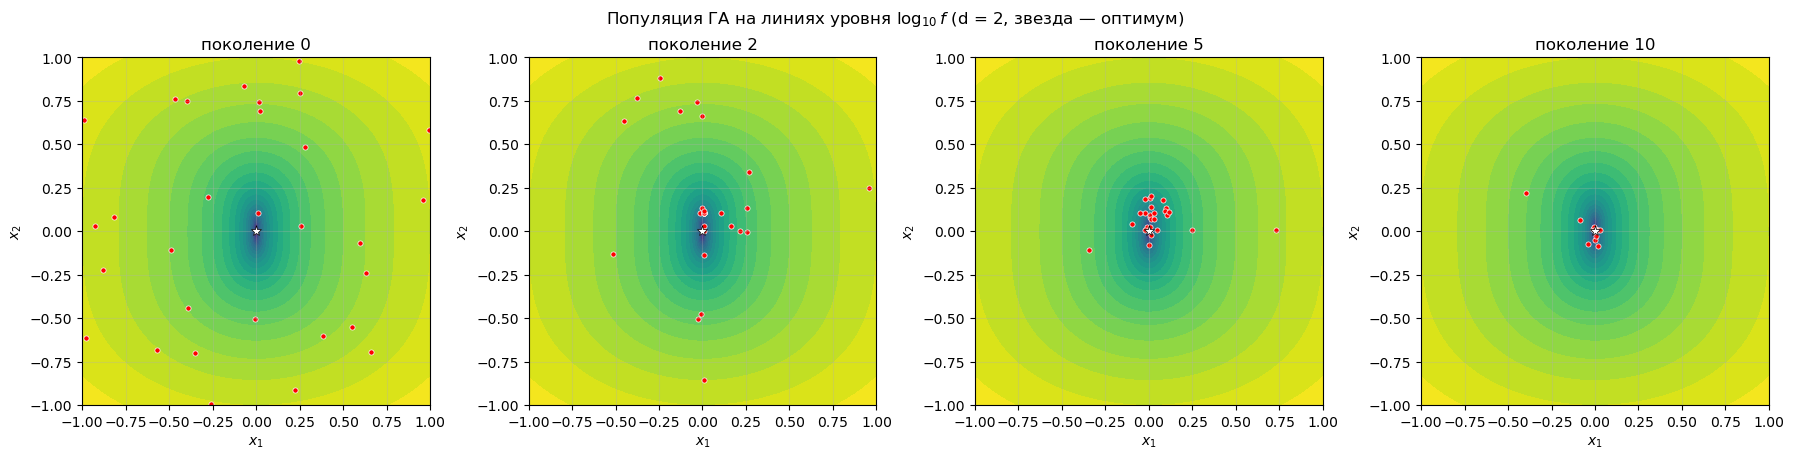

In [25]:
demo_cfg = replace(BASE, pop_size=30, pm=0.5, max_evals=30 + 40 * 28)   # при d=2: p_m = 1/d = 0.5, 40 поколений
snaps = run_ga(demo_cfg, seed=7, d=2, record_pop=True)["populations"]

g = np.linspace(LOW, HIGH, 300)
GX, GY = np.meshgrid(g, g)
GZ = sum_diff_powers(np.column_stack([GX.ravel(), GY.ravel()])).reshape(GX.shape)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, t in zip(axes, [0, 2, 5, 10]):
    ax.contourf(GX, GY, np.log10(GZ + 1e-12), levels=30, cmap="viridis")
    ax.scatter(snaps[t][:, 0], snaps[t][:, 1], c="red", s=14, edgecolor="white", lw=0.5)
    ax.plot(0, 0, "w*", ms=8, mec="black", mew=0.5)
    ax.set_title(f"поколение {t}")
    ax.set_xlim(LOW, HIGH); ax.set_ylim(LOW, HIGH); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
fig.suptitle("Популяция ГА на линиях уровня $\\log_{10} f$ (d = 2, звезда — оптимум)")
fig.tight_layout()
fig.savefig(RESULTS / "demo_d2_population.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Выводы

### 5.1. Факторы ($R = 30$, бюджет $10^4$)

| фактор | вариант | $\operatorname{med} f$ | успех | $p$ |
|---|---|---|---|---|
| мутация | **самоадаптивный $\sigma$** | $2 \cdot 10^{-11}$ | $100\%$ | — |
| | фикс. $\sigma = 0.1$ | $2 \cdot 10^{-8}$ | $43\%$ | $10^{-7}$ |
| | фикс. $\sigma = 0.01$ | $6 \cdot 10^{-9}$ | $73\%$ | $7 \cdot 10^{-8}$ |
| $\mu$ | **30** ($G = 356$) | $6 \cdot 10^{-13}$ | $100\%$ | $8 \cdot 10^{-7}$ |
| | 50 ($G = 207$) | $2 \cdot 10^{-11}$ | $100\%$ | — |
| | 100 | $7 \cdot 10^{-10}$ | $90\%$ | $10^{-5}$ |
| | 200 ($G = 49$) | $2 \cdot 10^{-7}$ | $0\%$ | $3 \cdot 10^{-11}$ |
| селекция | **ранговая** | $7 \cdot 10^{-12}$ | $100\%$ | $5 \cdot 10^{-3}$ |
| | турнир $k = 3$ | $2 \cdot 10^{-11}$ | $100\%$ | — |
| | рулетка | $6 \cdot 10^{-10}$ | $93\%$ | $8 \cdot 10^{-5}$ |
| кроссовер | **BLX-α** | $5 \cdot 10^{-18}$ | $100\%$ | $10^{-10}$ |
| | арифметический | $8 \cdot 10^{-14}$ | $100\%$ | $7 \cdot 10^{-7}$ |
| | SBX | $2 \cdot 10^{-11}$ | $100\%$ | — |

### 5.2. Что из этого следует

1. **Самоадаптация $\sigma$ — главное.** Фиксированный $\sigma$: большой → плато, малый → медленный старт.
2. **Меньше $\mu$ — лучше** (при этом бюджете): больше поколений $G$. Функция унимодальна → выгодна эксплуатация.
3. **Рулетка слабее:** $w_j = f_{\max} - f_j$ почти равны, когда $f_{\max} \to 0$ → давление селекции падает.
4. **BLX-α лучше не из-за центра:** на $f_s$ то же ($\operatorname{med} = 7 \cdot 10^{-19}$ против $1.5 \cdot 10^{-11}$ у SBX).
   Причина: разброс по координате $\propto I_i = |p^1_i - p^2_i|$ → шаг сам подстраивается под каждую $x_i$ (анизотропия).
5. Выводы 2–3 **не переносятся** на многоэкстремальные функции (там малое $\mu$ и сильное давление → преждевременная сходимость).

### 5.3. Почему результат хороший

* $f^* = 0$ известен → ошибка $= f$
* $30/30$ запусков: $f < 10^{-8}$, худший $2.7 \cdot 10^{-9}$, $s = 7 \cdot 10^{-10}$ → устойчиво, не единичный запуск
* Лучше случайного поиска на $\sim 9$ порядков, локального — на $4$–$7$, $p = 3 \cdot 10^{-11}$
* **Ограничение:** $f$ выпукла → градиентный метод или (1+1)-ES с правилом 1/5 тоже бы справились

### 5.4. Дополнительное задание

* самоадаптивный $\sigma$ (логнормальный)
* ранговая селекция
* кроссоверы SBX, BLX-α, арифметический
* визуализация популяции при $d = 2$